# Analisis Hasil Evaluasi — per Domain & Panjang Dialog

Notebook **mandiri** (terpisah dari EDA) untuk menganalisis skor evaluasi model per kategori.
Memecah metrik per **domain** dan per **bin panjang dialog**, dengan uji signifikansi dan koreksi
bias re-weighting ke populasi.

**Metrik didukung (auto-deteksi):** ROUGE, BERTScore, coherence, relevance, fluency, consistency,
AlignScore — atau kolom numerik apa pun di file hasil.

**Input yang dibutuhkan:**
- `RESULTS_PATH` — file skor per dialog (CSV/JSON), satu baris per dialog.
- teks dialog: lewat kolom di file hasil (`DIALOG_COL`), **atau** file dialog terpisah sejajar urutan.
- (opsional) `POP_PATH` — populasi penuh, hanya untuk koreksi bias re-weighting.

## 0. Setup

In [1]:
import pandas as pd, numpy as np, re, warnings
import matplotlib.pyplot as plt
from scipy.stats import f_oneway, kruskal
warnings.filterwarnings("ignore")
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3

# ===================== KONFIG =====================
RESULTS_PATH = "method4"   # skor per dialog (CSV/JSON)
DIALOG_COL   = None            # nama kolom teks dialog di RESULTS_PATH; None = auto / pakai file terpisah
DIALOG_PATH  = "data/all_dialogue_test_500.json"           # file dialog terpisah (mis. "multiwoz_sampled_2500_test.json") jika hasil tak punya teks
DIALOG_TEXT_COL = 0            # kolom teks di DIALOG_PATH
POP_PATH     = None            # populasi penuh utk re-weighting panjang (opsional); None = lewati
POP_TEXT_COL = 0
N_LEN_BINS   = 3               # jumlah bin panjang (3 = short/medium/long)
# ==================================================

## 1. Deteksi Domain & Panjang

In [2]:
DOMAIN_KEYWORDS = {
    "hotel":      ["hotel","guesthouse","guest house","stay","room","lodge","star"],
    "restaurant": ["restaurant","eat","food","dine","dinner","lunch","cuisine","table"],
    "taxi":       ["taxi","cab","pick me up","pickup"],
    "train":      ["train","departure","arrive by","leave after","trainid"],
    "attraction": ["attraction","museum","park","college","gallery","nightclub","theatre"],
}
def detect_domains(text):
    t = str(text).lower()
    return [d for d,kws in DOMAIN_KEYWORDS.items() if any(k in t for k in kws)]
def n_words(text):
    return len(re.findall(r"\w+", str(text)))

In [3]:
import json
import yaml
from pathlib import Path
from statistics import mean
import pandas as pd

def load_yaml(path: str | Path) -> dict:
    """Memuat file YAML dan mengembalikan dictionary kosong jika file tidak valid."""
    filepath = Path(path)
    if not filepath.is_file():
        raise FileNotFoundError(f"File konfigurasi tidak ditemukan: {filepath}")
    
    with open(filepath, "r", encoding="utf-8") as f:
        return yaml.safe_load(f) or {}

def load_json(path: str | Path) -> dict | list:
    """Memuat file JSON."""
    filepath = Path(path)
    if not filepath.is_file():
        raise FileNotFoundError(f"File JSON tidak ditemukan: {filepath}")
        
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)

def get_rouge_score(method_num: str, path: str) -> dict:
    """Memuat skor ROUGE dari path yang ditentukan."""
    new_path = Path(f"{method_num}_outputs") / path / "rouge.json"
    return load_json(new_path)

def get_generated_file(method_num:str, path:str) -> dict:
    new_path = Path(f"{method_num}_outputs") / path / "generated.json"
    data = load_json(new_path)
    result = {
        key: [d[key] for d in data]
        for key in data[0]
    }
    return result

def reformat_unieval(unieval: list) -> dict:
    """Menghitung nilai rata-rata untuk setiap metrik UniEval."""
    if not unieval:
        return {}
        
    coherence = [item.get('coherence', 0) for item in unieval]
    relevance = [item.get('relevance', 0) for item in unieval]
    fluency = [item.get('fluency', 0) for item in unieval]
    consistency = [item.get('consistency', 0) for item in unieval]

    return {
        "coherence": coherence,
        "relevance": relevance,
        "fluency": fluency,
        "consistency": consistency
    }
    
def get_unieval_score(method_num: str, path: str) -> dict:
    """Memuat skor UniEval dari path yang ditentukan lalu merapihkannya."""
    new_path = Path(f"{method_num}_outputs") / path / "unieval.json"
    unieval_data = load_json(new_path)
    return reformat_unieval(unieval_data)
    # Menampilkan DataFrame

def get_align_score(method_num:str, path: str) -> dict:
    new_path = Path(f"{method_num}_outputs") / path / "alignscore.json"
    align_score_data = load_json(new_path)
    return { "align_score" : align_score_data}

# Setup konfigurasi
def read_result(method_num, path):
    method_cfg = load_yaml(f"configs/methods/{method_num}.yaml")
    
    dataset_path = method_cfg.get('datasets')
    if dataset_path:
        dataset_cfg = load_yaml(f"configs/datasets/{dataset_path}")
    
    # Memuat list eksperimen
    experiments = method_cfg.get('experiments', [])
    
    # Mengumpulkan nama folder output dari tiap eksperimen
    
    # Jika ingin langsung mengambil skor metrik, Anda bisa melakukan iterasi pada folder_list:
    
    rouge = get_rouge_score(method_num, path)
    generated = get_generated_file(method_num, path)
    unieval_mean = get_unieval_score(method_num, path)
    align_score_mean = get_align_score(method_num, path)
    rows = {
            **unieval_mean,
            **align_score_mean,
            **generated
    }
    df = pd.DataFrame(rows)
    # Mengubah list of dictionaries menjadi DataFrame
    return df

## 2. Load Hasil & Join Teks Dialog

In [4]:
# --- load skor ---
res = read_result(RESULTS_PATH, "bart_margin_part")
res = res.reset_index(drop=True)
print("Kolom hasil:", list(res.columns), "| baris:", len(res))

# --- deteksi kolom metrik numerik ---
KNOWN = ["coherence",
         "relevance","fluency","consistency","alignscore","align_score"]
metric_cols = [c for c in res.columns if pd.api.types.is_numeric_dtype(res[c])
               and any(k in c.lower() for k in KNOWN)]
if not metric_cols:
    metric_cols = [c for c in res.columns if pd.api.types.is_numeric_dtype(res[c])]
print("Metrik terdeteksi:", metric_cols)
assert metric_cols, "Tidak ada kolom metrik numerik terdeteksi."

# --- dapatkan teks dialog ---
auto = [c for c in res.columns if c.lower() in ("dialogue","dialog","text","input","source")]
if DIALOG_COL and DIALOG_COL in res.columns:
    texts = res[DIALOG_COL].astype(str)
elif auto:
    texts = res[auto[0]].astype(str); print(f"(teks dari kolom '{auto[0]}')")
elif DIALOG_PATH:
    dlg = pd.read_json(DIALOG_PATH)
    col = DIALOG_TEXT_COL if DIALOG_TEXT_COL in dlg.columns else dlg.columns[0]
    texts = dlg[col].astype(str).reset_index(drop=True)
    assert len(texts) == len(res), f"Baris dialog ({len(texts)}) != hasil ({len(res)}); urutan harus sejajar."
    print(f"(teks dari file terpisah '{DIALOG_PATH}', sejajar urutan)")
else:
    raise ValueError("Teks dialog tak ditemukan. Set DIALOG_COL atau DIALOG_PATH.")

res["_domains"] = texts.apply(detect_domains).values
res["_nwords"]  = texts.apply(n_words).values

# --- bin panjang via kuantil (seimbang) ---
qs = [i/N_LEN_BINS for i in range(1, N_LEN_BINS)]
edges = res["_nwords"].quantile(qs).tolist()
labels = (["short","medium","long"] if N_LEN_BINS==3
          else [f"bin{i+1}" for i in range(N_LEN_BINS)])
def length_bin(w):
    for i,e in enumerate(edges):
        if w <= e: return labels[i]
    return labels[-1]
res["_lenbin"] = res["_nwords"].apply(length_bin)
print("Batas bin:", [round(e) for e in edges])
print(res["_lenbin"].value_counts().to_dict())

Kolom hasil: ['coherence', 'relevance', 'fluency', 'consistency', 'align_score', 'prompt', 'prediction', 'reference'] | baris: 499
Metrik terdeteksi: ['coherence', 'relevance', 'fluency', 'consistency', 'align_score']
(teks dari file terpisah 'data/all_dialogue_test_500.json', sejajar urutan)
Batas bin: [123, 220]
{'medium': 167, 'short': 166, 'long': 166}


In [5]:
res.describe()

,coherence,relevance,fluency,consistency,align_score,_nwords
count,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000
mean,0.906031,0.898035,0.842269,0.899592,0.794544,178.402806
std,0.139390,0.158232,0.107496,0.067943,0.125785,86.823738
min,0.034989,0.038233,0.393229,0.539734,0.374972,33.000000
25%,0.910292,0.907291,0.774050,0.879474,0.708733,103.000000
50%,0.956960,0.956808,0.886759,0.924241,0.809532,166.000000
75%,0.972528,0.976517,0.923982,0.945599,0.901545,245.000000
max,0.991712,0.992426,0.954016,0.970845,0.991049,457.000000


In [6]:
res[['coherence','relevance','fluency','consistency','align_score']].quantile(0.1)

coherence      0.781180
relevance      0.740326
fluency        0.695015
consistency    0.802455
align_score    0.620306
Name: 0.1, dtype: float64

## 3. Hasil per Domain

Satu dialog bisa menyentuh beberapa domain, jadi baris di-*explode*: dialog multi-domain
berkontribusi ke tiap domain yang relevan.

Jumlah dialog per domain: {'restaurant': 400, 'attraction': 230, 'hotel': 214, 'train': 153, 'taxi': 90}
SKOR RATA-RATA PER DOMAIN


,coherence,relevance,fluency,consistency,align_score
_domains,,,,,
attraction,0.900,0.897,0.823,0.894,0.775
hotel,0.904,0.891,0.833,0.900,0.787
restaurant,0.905,0.900,0.839,0.900,0.797
taxi,0.901,0.919,0.810,0.890,0.771
train,0.901,0.877,0.824,0.891,0.802


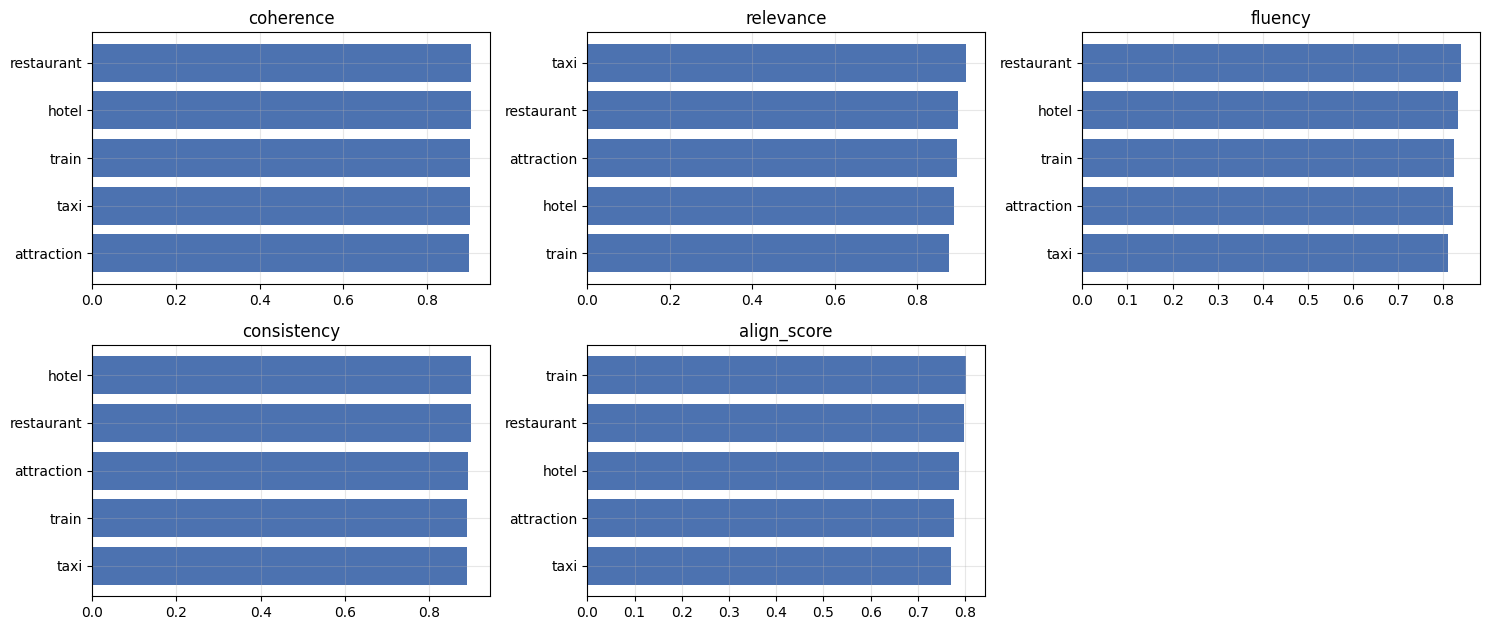

In [7]:
dom_rows = res.explode("_domains").dropna(subset=["_domains"])
tab_domain = dom_rows.groupby("_domains")[metric_cols].mean().round(3)
cnt_domain = dom_rows["_domains"].value_counts()
print("Jumlah dialog per domain:", cnt_domain.to_dict())
print("="*60, "\nSKOR RATA-RATA PER DOMAIN\n", "="*60)
display(tab_domain)

n=len(metric_cols); ncol=3; nrow=int(np.ceil(n/ncol))
fig,axes=plt.subplots(nrow,ncol,figsize=(5*ncol,3.2*nrow)); axes=np.array(axes).ravel()
for ax,m in zip(axes,metric_cols):
    g=dom_rows.groupby("_domains")[m].mean().sort_values()
    ax.barh(g.index,g.values,color="#4C72B0"); ax.set_title(m)
    ax.set_xlim(left=min(0,g.min()*0.95))
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Hasil per Bin Panjang + Uji Signifikansi

SKOR RATA-RATA PER BIN PANJANG


,coherence,relevance,fluency,consistency,align_score
_lenbin,,,,,
short,0.937,0.947,0.891,0.918,0.810
medium,0.918,0.892,0.832,0.901,0.810
long,0.863,0.855,0.803,0.880,0.764


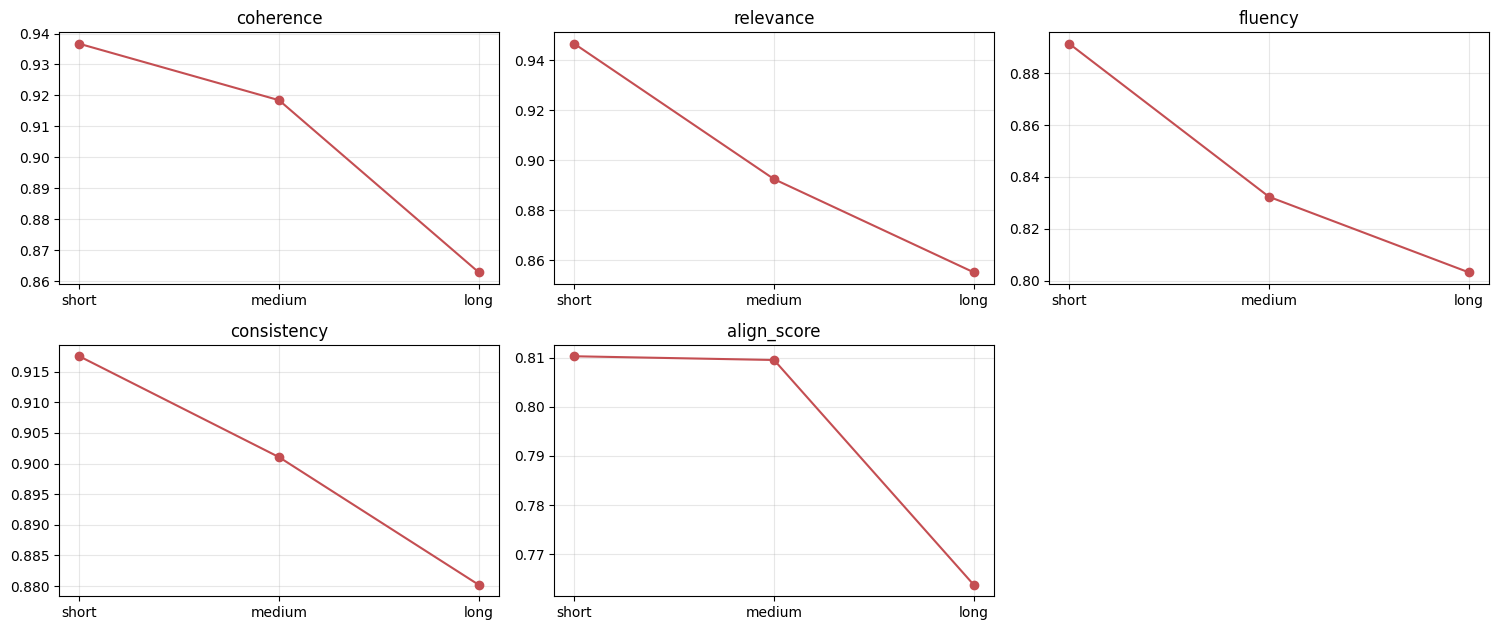

Uji beda skor antar bin panjang
------------------------------------------------------------
coherence      ANOVA p=2.45e-06 | Kruskal p=0.016 -> **SIGNIFIKAN**
relevance      ANOVA p=5.71e-07 | Kruskal p=2.33e-10 -> **SIGNIFIKAN**
fluency        ANOVA p=4.92e-14 | Kruskal p=3.29e-15 -> **SIGNIFIKAN**
consistency    ANOVA p=2.61e-06 | Kruskal p=1.32e-06 -> **SIGNIFIKAN**
align_score    ANOVA p=0.000531 | Kruskal p=5.52e-05 -> **SIGNIFIKAN**

INSIGHT:
- p<0.05 => panjang dialog BERPENGARUH ke skor; laporkan hasil per-bin & bias panjang relevan dikoreksi.
- p>0.05 => skor stabil lintas panjang; bias panjang sampel tidak berdampak ke metrik itu.


In [8]:
order=[l for l in ["short","medium","long"] if l in res["_lenbin"].unique()] or labels
tab_len = res.groupby("_lenbin")[metric_cols].mean().reindex(order).round(3)
print("="*60, "\nSKOR RATA-RATA PER BIN PANJANG\n", "="*60)
display(tab_len)

fig,axes=plt.subplots(nrow,ncol,figsize=(5*ncol,3.2*nrow)); axes=np.array(axes).ravel()
for ax,m in zip(axes,metric_cols):
    g=res.groupby("_lenbin")[m].mean().reindex(order)
    ax.plot(order,g.values,"o-",color="#C44E52"); ax.set_title(m)
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

print("Uji beda skor antar bin panjang\n"+"-"*60)
for m in metric_cols:
    groups=[res[res["_lenbin"]==b][m].dropna() for b in order]
    if all(len(g)>1 for g in groups):
        F,pf=f_oneway(*groups); H,pk=kruskal(*groups)
        sig="**SIGNIFIKAN**" if pk<0.05 else "tidak signifikan"
        print(f"{m:14s} ANOVA p={pf:.3g} | Kruskal p={pk:.3g} -> {sig}")
print("""
INSIGHT:
- p<0.05 => panjang dialog BERPENGARUH ke skor; laporkan hasil per-bin & bias panjang relevan dikoreksi.
- p>0.05 => skor stabil lintas panjang; bias panjang sampel tidak berdampak ke metrik itu.""")

## 5. Koreksi Bias — Re-weighting ke Populasi (opsional)

Hanya jalan bila `POP_PATH` diisi. Menghitung skor seandainya komposisi panjang sampel = populasi.

In [9]:
if POP_PATH:
    popdf = pd.read_json(POP_PATH)
    pcol = POP_TEXT_COL if POP_TEXT_COL in popdf.columns else popdf.columns[0]
    pop_nwords = popdf[pcol].astype(str).apply(n_words)
    pop_share = pop_nwords.apply(length_bin).value_counts(normalize=True)
    smp_share = res["_lenbin"].value_counts(normalize=True)
    w = (pop_share/smp_share).to_dict()
    res["_w"] = res["_lenbin"].map(w)
    print("Bobot per bin (pop/sample):", {k:round(v,3) for k,v in w.items()})

    rows=[]
    for m in metric_cols:
        naive=res[m].mean()
        sub=res[res[m].notna()]
        wm=np.average(sub[m], weights=sub["_w"])
        rows.append({"metric":m,"naive_mean":round(naive,3),
                     "pop_reweighted":round(wm,3),"selisih":round(wm-naive,3)})
    display(pd.DataFrame(rows))
    print("""INSIGHT:
- selisih |<0.01| => bias panjang nyaris tak menggeser skor; mean biasa aman dilaporkan.
- selisih besar    => laporkan versi re-weighted agar mewakili populasi.""")
else:
    print("POP_PATH kosong -> langkah re-weighting dilewati. Isi POP_PATH untuk mengaktifkan.")

POP_PATH kosong -> langkah re-weighting dilewati. Isi POP_PATH untuk mengaktifkan.


## 6. Ekspor Tabel (untuk paper)

In [10]:
tab_domain.to_csv("results_by_domain.csv")
tab_len.to_csv("results_by_length.csv")
print("Tersimpan: results_by_domain.csv, results_by_length.csv")
print("\nLaTeX per domain:\n")
print(tab_domain.to_latex(float_format="%.3f"))

Tersimpan: results_by_domain.csv, results_by_length.csv

LaTeX per domain:

\begin{tabular}{lrrrrr}
\toprule
 & coherence & relevance & fluency & consistency & align_score \\
_domains &  &  &  &  &  \\
\midrule
attraction & 0.900 & 0.897 & 0.823 & 0.894 & 0.775 \\
hotel & 0.904 & 0.891 & 0.833 & 0.900 & 0.787 \\
restaurant & 0.905 & 0.900 & 0.839 & 0.900 & 0.797 \\
taxi & 0.901 & 0.919 & 0.810 & 0.890 & 0.771 \\
train & 0.901 & 0.877 & 0.824 & 0.891 & 0.802 \\
\bottomrule
\end{tabular}



In [11]:
# ============================================================
#  CEK MANUAL TERARAH — dialog + reference + prediksi + skor
#  Tempel sebagai sel baru di akhir notebook (butuh: res, metric_cols, texts)
# ============================================================
import pandas as pd, numpy as np, re, textwrap

# --- auto-deteksi kolom prediksi & reference (atau set manual di sini) ---
PRED_COL = 'prediction'      # mis. "prediction" / "summary" / "generated"
REF_COL  = 'reference'      # mis. "reference" / "target" / "gold"
PRED_CANDS = ["prediction","pred","summary","generated","hypothesis","output","gen_summary","candidate"]
REF_CANDS  = ["reference","ref","target","gold","gt","label","gold_summary","ground_truth"]

def _find(cands):
    for c in res.columns:
        if c.lower() in cands: return c
    for c in res.columns:                      # partial match
        if any(k in c.lower() for k in cands): return c
    return None

PRED_COL = PRED_COL or _find(PRED_CANDS)
REF_COL  = REF_COL  or _find(REF_CANDS)
print("Kolom prediksi :", PRED_COL)
print("Kolom reference:", REF_COL)
if PRED_COL is None or REF_COL is None:
    print("\n!! Tidak terdeteksi otomatis. Kolom tersedia:", list(res.columns))
    print("   Set PRED_COL / REF_COL manual lalu jalankan ulang sel ini.")

# --- pastikan fitur kategori tersedia di res ---
if "_nwords" not in res.columns:
    res["_nwords"] = pd.Series(texts).reset_index(drop=True).apply(lambda t: len(re.findall(r"\w+", str(t))))
if "_dialogue" not in res.columns:
    res["_dialogue"] = pd.Series(texts).reset_index(drop=True).values

# pilih metrik faktual & fluency utk seleksi (fallback ke yang ada)
def pick(name, default):
    hit=[m for m in metric_cols if name in m.lower()]
    return hit[0] if hit else default
ALIGN = pick("align", metric_cols[-1])
FLU   = pick("fluency", metric_cols[0])
CONS  = pick("consist", metric_cols[0])

def show(idx, judul):
    print("\n"+"="*78); print(judul); print("="*78)
    for i in idx:
        r=res.loc[i]
        print(f"\n[row {i}]  panjang={int(r['_nwords'])} kata  | " +
              " ".join(f"{m}={r[m]:.3f}" for m in metric_cols))
        dlg=str(r["_dialogue"]).replace("\n"," ⏎ ")
        print("  DIALOG :", textwrap.shorten(dlg, 300))
        if REF_COL:  print("  REF    :", textwrap.shorten(str(r[REF_COL]), 220))
        if PRED_COL: print("  PRED   :", textwrap.shorten(str(r[PRED_COL]), 220))

K=3  # jumlah contoh per kelompok

# 1) dialog panjang + align rendah  (inti temuan: faktualitas turun saat panjang)
long_thr = res["_nwords"].quantile(0.66)
g1 = res[res["_nwords"]>=long_thr].nsmallest(K, ALIGN).index
show(g1, f"1) DIALOG PANJANG + {ALIGN} TERENDAH  (kenapa faktualitas turun di dialog panjang?)")

# 2) domain taxi + align rendah (anomali taxi: lancar tapi kurang akurat)
if "_domains" in res.columns:
    taxi = res[res["_domains"].apply(lambda ds: "taxi" in ds if isinstance(ds,list) else False)]
    if len(taxi): show(taxi.nsmallest(K, ALIGN).index, f"2) DOMAIN TAXI + {ALIGN} TERENDAH")

# 3) disagreement: fluency tinggi tapi konsistensi/align rendah ("terbaca bagus tapi salah")
zf=(res[FLU]-res[FLU].mean())/res[FLU].std()
za=(res[ALIGN]-res[ALIGN].mean())/res[ALIGN].std()
res["_gap"]=zf-za
show(res.nlargest(K,"_gap").index, f"3) {FLU} TINGGI tapi {ALIGN} RENDAH  (terbaca bagus tapi tidak akurat)")

# 4) skor terendah & tertinggi keseluruhan (sanity check metrik)
res["_avg"]=res[metric_cols].mean(axis=1)
show(res.nsmallest(K,"_avg").index, "4a) SKOR RATA-RATA TERENDAH (apakah memang summary buruk?)")
show(res.nlargest(K,"_avg").index, "4b) SKOR RATA-RATA TERTINGGI (sanity check)")

# ekspor untuk dibaca di luar
cols=["_nwords"]+metric_cols+[c for c in [REF_COL,PRED_COL] if c]+["_dialogue"]
sel_idx=list(dict.fromkeys(list(g1)+list(res.nlargest(K,"_gap").index)+list(res.nsmallest(K,"_avg").index)))
res.loc[sel_idx, cols].to_csv("manual_check_samples.csv", index_label="row")
print("\n>> Disimpan: manual_check_samples.csv")


Kolom prediksi : prediction
Kolom reference: reference

1) DIALOG PANJANG + align_score TERENDAH  (kenapa faktualitas turun di dialog panjang?)

[row 464]  panjang=262 kata  | coherence=0.965 relevance=0.973 fluency=0.819 consistency=0.890 align_score=0.404
  DIALOG : user: Do you book trains for the bishops stortford? ⏎ agent: Yes. Are you departing or arriving in bishops stortford? ⏎ user: I am going there from Cambridge on Thursday. ⏎ agent: I have 10 trains going to Bishops Stortford from Cambridge on Thursday. What time do you need to arrive? ⏎ user: I [...]
  REF    : User Profile: Traveler going from Cambridge to Bishop’s Stortford, flexible on restaurant cuisine, interested in British food when Austrian isn’t available. Problem: Needs train tickets from Cambridge to Bishop’s [...]
  PRED   : Profile: Traveler going from Cambridge to Bishop’s Stortford on Thursday, interested in British cuisine in the city centre. Problem: Needed to book train tickets from Cambridge and find a n

In [12]:
%pip install openpyxl


[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: /home/qiscus/Coresearch_ITB_Qiscus/repo_alan/SLM Summarization/symbolic_distill_contrastive_summ/venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
res.loc[sel_idx, cols].to_excel("manual_check_samples.xlsx", index_label="row")
